In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.model_selection import StratifiedShuffleSplit
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             confusion_matrix,
                             roc_auc_score,
                             roc_curve,
                             auc)

SEED = 67

In [52]:
upload = drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

In [54]:
df_data = pd.read_csv("/content/drive/MyDrive/dataset/credit_card_fraud/creditcard.csv")

### EDA

In [55]:
df_data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [56]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [57]:
df_data.shape

(284807, 31)

### PREPROCESSING

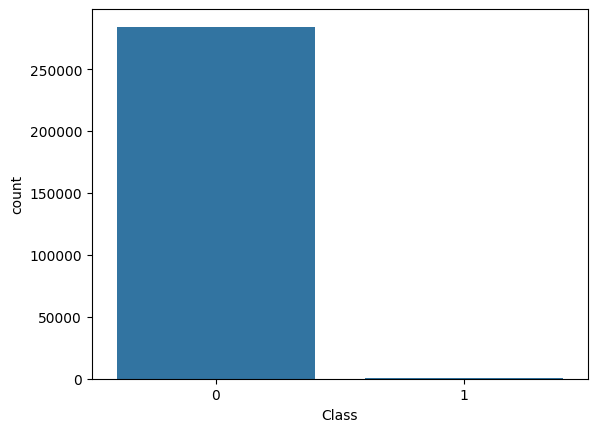

In [58]:
sns.countplot(x="Class", data=df_data)
plt.show()

In [59]:
df_data["Class"].value_counts()

,count
Class,
0,284315
1,492


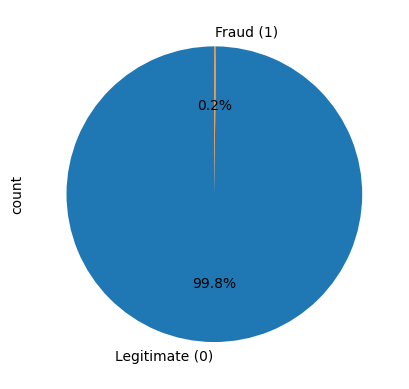

In [77]:
df_data["Class"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1f77b4", "#ff7f0e"],
    labels=["Legitimate (0)", "Fraud (1)"],
)
plt.show()

In [61]:
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
df_train, df_test = None, None

for train_idx, test_idx in split.split(df_data, df_data["Class"]):
  df_train = df_data.iloc[train_idx]
  df_test = df_data.iloc[test_idx]

In [62]:
X_train, y_train = df_train.drop(columns=["Class"], axis=1), df_train["Class"]
X_test, y_test = df_test.drop(columns=["Class"], axis=1), df_test["Class"]

In [63]:
smote = SMOTE(random_state=SEED)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

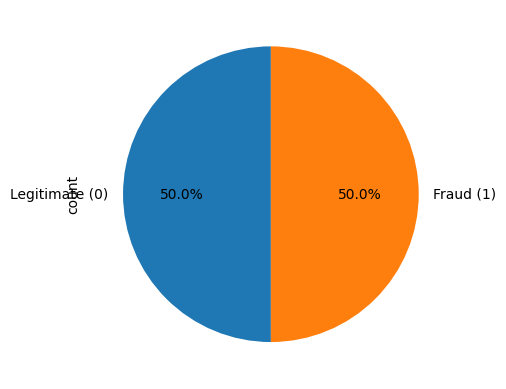

In [78]:
y_train_resampled.value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1f77b4", "#ff7f0e"],
    labels=["Legitimate (0)", "Fraud (1)"],
)
plt.show()

### MODELING

In [65]:
results = dict()

Tanpa Resampling

In [66]:
xgb = XGBClassifier(eval_metric="logloss", random_state=SEED)
xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)

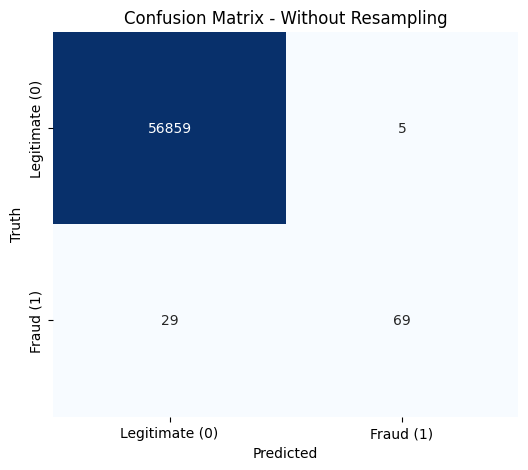

In [67]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"],
)

plt.xlabel("Predicted")
plt.ylabel("Truth")
plt.title("Confusion Matrix - Without Resampling")
plt.show()

In [68]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

results["no_resampling"] = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1
}

print(f"accuracy: {accuracy}")
print(f"precision: {precision}")
print(f"recall: {recall}")
print(f"f1: {f1}")

accuracy: 0.999403110845827
precision: 0.9324324324324325
recall: 0.7040816326530612
f1: 0.8023255813953488


ROC-AUC Score: 0.9439


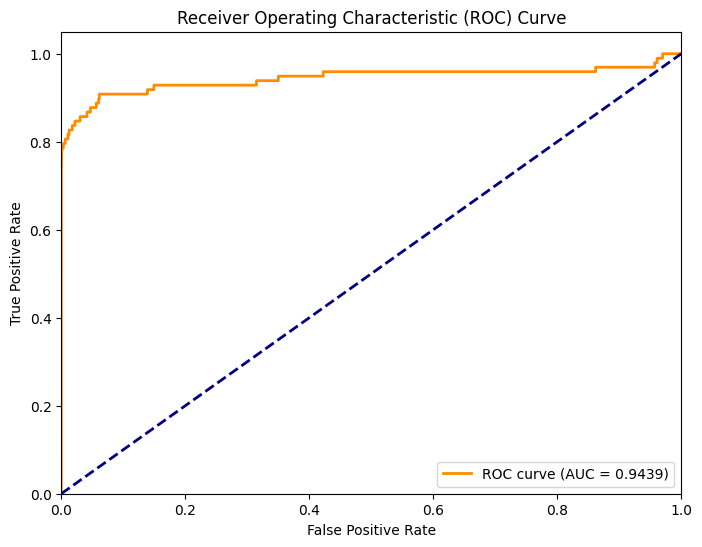

In [79]:
y_pred_proba = xgb.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="navy", lw=2, linestyle="--"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()

In [70]:
print("\nClassification Report: ")
print(classification_report(y_test, y_pred))


Classification Report: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.93      0.70      0.80        98

    accuracy                           1.00     56962
   macro avg       0.97      0.85      0.90     56962
weighted avg       1.00      1.00      1.00     56962



Dengan Resampling (SMOTE)

In [71]:
xgb_resampled = XGBClassifier(eval_metric="logloss", random_state=SEED)
xgb_resampled.fit(X_train_resampled, y_train_resampled)

y_pred_resampled = xgb_resampled.predict(X_test)


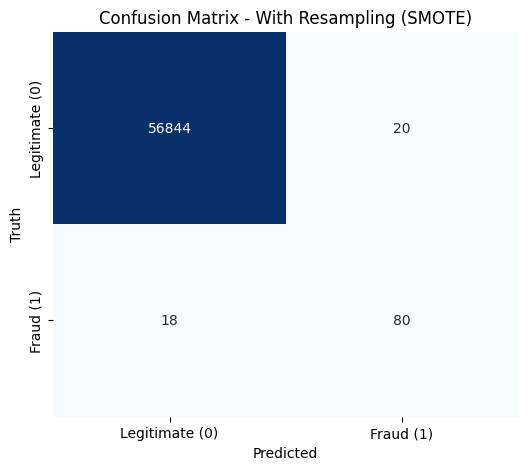

In [72]:
cm = confusion_matrix(y_test, y_pred_resampled)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"],
)

plt.xlabel("Predicted")
plt.ylabel("Truth")
plt.title("Confusion Matrix - With Resampling (SMOTE)")
plt.show()

In [73]:
accuracy = accuracy_score(y_test, y_pred_resampled)
precision = precision_score(y_test, y_pred_resampled)
recall = recall_score(y_test, y_pred_resampled)
f1 = f1_score(y_test, y_pred_resampled)

results["resampling"] = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1
}

print(f"accuracy: {accuracy}")
print(f"precision: {precision}")
print(f"recall: {recall}")
print(f"f1: {f1}")

accuracy: 0.9993328885923949
precision: 0.8
recall: 0.8163265306122449
f1: 0.8080808080808081


ROC-AUC Score: 0.9795


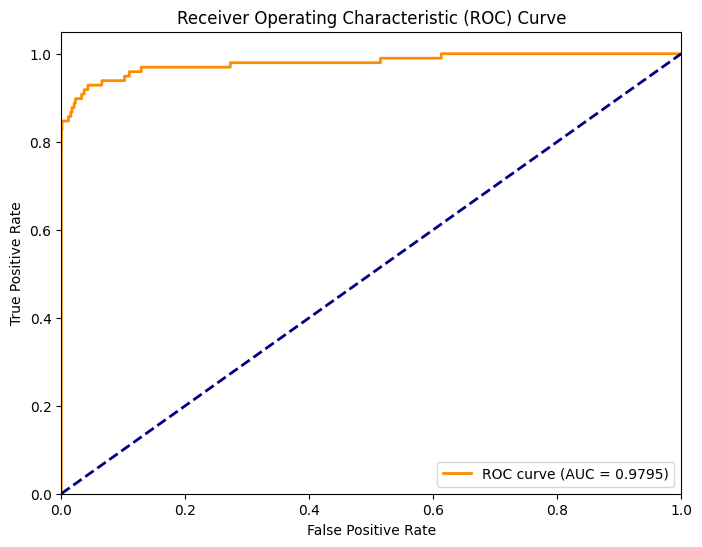

In [74]:
y_pred_proba = xgb_resampled.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="navy", lw=2, linestyle="--"
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()

In [75]:
print("\nClassification Report: ")
print(classification_report(y_test, y_pred_resampled))


Classification Report: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.80      0.82      0.81        98

    accuracy                           1.00     56962
   macro avg       0.90      0.91      0.90     56962
weighted avg       1.00      1.00      1.00     56962



### EVALUASI MODEL

Akurasi disini tidak cukup untuk menilai sebuah model, karena imbalance pada dataset yang dimana ada ~99.8% data yang label Classnya normal

Ini artinya, jika kita memiliki model yang bodoh yang tidak melakukan apa-apa dan hanya menebak label sebagai 0 (normal) setiap saat, maka model kita akan tetap memiliki akurasi ~99.8% (sangat tinggi)

Maka dari itu, kita perlu menggunakan metric yang tidak bergantung pada benar atau tidaknya suatu tebakan saja, disini kita menggunakan f1 score dan roc curve

In [76]:
pd.DataFrame(results).T

,accuracy,precision,recall,f1
no_resampling,0.999403,0.932432,0.704082,0.802326
resampling,0.999333,0.800000,0.816327,0.808081
